In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 
print("ML environment ready")

ML environment ready


In [2]:
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [4]:
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

(353, 10)
(89, 10)


In [5]:
from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(
X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])


Slope: 998.5776891375592
Intercept: 152.00335421448167
First 5 predictions: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


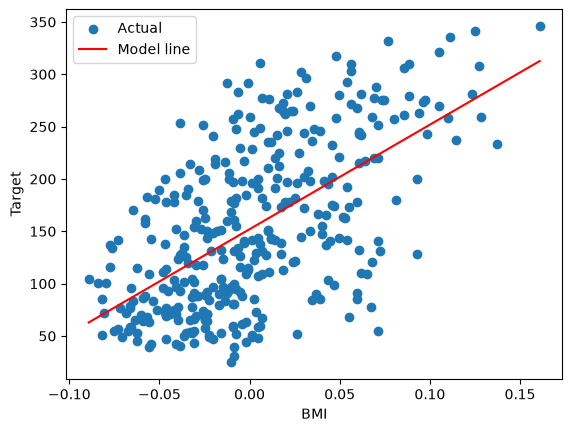

In [6]:
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
Xtr["bmi"].values[order],
pred_train[order],
color="red", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.legend()
plt.show()

In [7]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]


In [8]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]


In [11]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)

MSE: 2900.193628493482


In [13]:
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
db = (-2/len(x))*np.sum(y_demo-yhat)
m -= lr*dm
b -= lr*db
print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))

0.44 0.12
Prediction at x=6: 2.76


In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

models = {
"Ridge": Ridge(alpha=1.0),
"Lasso": Lasso(alpha=0.1, max_iter=10000),
"ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

for name, alg in models.items():
                             pipe = make_pipeline(StandardScaler(), alg)
pipe.fit(X_train, y_train)
p = pipe.predict(X_test)

print(name, "R2:", round(r2_score(y_test, p), 3))

ElasticNet R2: 0.459


In [22]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        22:30:30   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

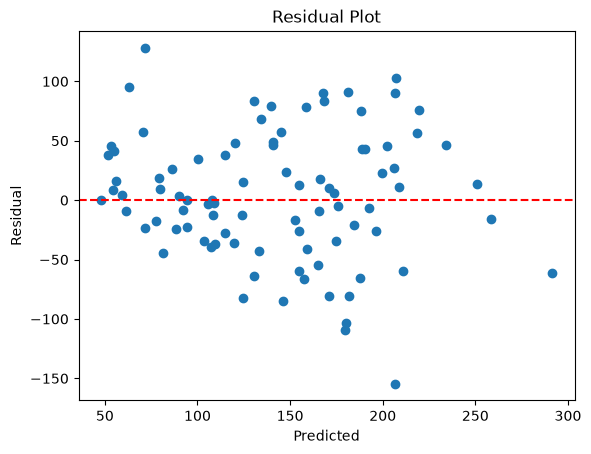

In [23]:
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

ML environment ready
(442, 11)
X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
Slope: 998.5776891375592
Intercept: 152.00335421448167
First 5 predictions: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


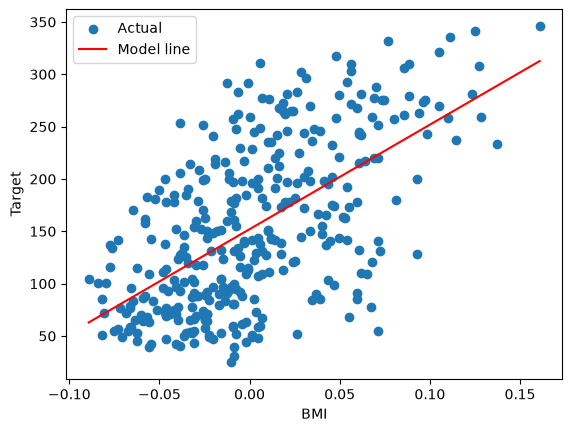

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]
MSE: 2900.193628493482
0.44 0.12
Prediction at x=6: 2.76
ElasticNet R2: 0.459


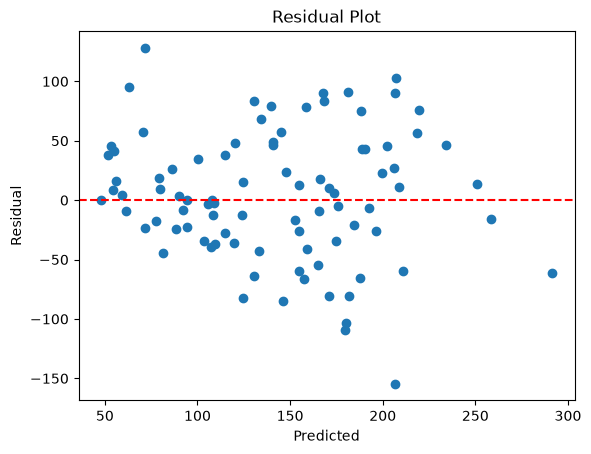

10 3815.5854342370912 3979.5095324580307
MAE: 42.794094679599944
MSE: 2900.193628493482
RMSE: 53.85344583676593
R2: 0.45260276297191937


In [26]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 
print("ML environment ready")
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())
from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(
X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
Xtr["bmi"].values[order],
pred_train[order],
color="red", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.legend()
plt.show()
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
db = (-2/len(x))*np.sum(y_demo-yhat)
m -= lr*dm
b -= lr*db
print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

models = {
"Ridge": Ridge(alpha=1.0),
"Lasso": Lasso(alpha=0.1, max_iter=10000),
"ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

for name, alg in models.items():
                             pipe = make_pipeline(StandardScaler(), alg)
pipe.fit(X_train, y_train)
p = pipe.predict(X_test)

print(name, "R2:", round(r2_score(y_test, p), 3))
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

for degree in [1, 2, 5, 10]:
 model = make_pipeline(
PolynomialFeatures(degree),
LinearRegression()

)

model.fit(X_train[["bmi"]], y_train)
tr = model.predict(X_train[["bmi"]])
te = model.predict(X_test[["bmi"]])

print(degree,

mean_squared_error(y_train,tr),
mean_squared_error(y_test,te))
# Compare train and test errors
# using the degree loop from the

# previous slide.

# Low train error + high test error:
# possible high variance.

# High train error + high test error:

# possible high bias.
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)

mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, pred_multi)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)